# Supplementary figure: stability of the TSS ranking by Cohen's *d*

Supplement to Figure 6 (`fig6_tss_interpretation.ipynb`). Re-plots source data only (no_deep cohort); no
analysis of its own.

| panel | what is drawn | source data (`data/no_deep/`) | exporter |
|---|---|---|---|
| a | Spearman correlation of Cohen's *d* between two rankings of the 14,221 TSSs | `figS17_stability_cohen_d.csv` | `export/export_figS17_cohen_d.py` |
| b | Jaccard index of the top-*k* sets of two disjoint halves and with permuted labels | `figS17_stability_cohen_d.csv` | `export/export_figS17_cohen_d.py` |
| c | Jaccard index of the top-*k* sets of two outer folds: Cohen's *d* and model coefficients | `figS17_stability_cohen_d.csv`, `figS17_stability.csv` | `export/export_figS17.py`, `export/export_figS17_cohen_d.py` |
| d | agreement between pairs of cancer types, Cohen's *d* | `figS_loco_consistency_matrix.csv`, `figS_loco_consistency_summary.json` | `export/export_figS_loco_consistency.py` |
| e | agreement between pairs of cancer types, model coefficients | same | same |

`SHOW_SINGLE_TSS = True` (first code cell, default `False`) adds a top row of three single-TSS panels
(distribution of Cohen's *d*, BH *q* against *d*, single-TSS AUROC against rank; source
`figS17_tss_effects_{task}.csv`, `figS17_tss_cohen_d.csv`); the panels of the table then become d to h.

Sign convention: Cohen's *d* = cancer − healthy of the dip depth at the TSS (*d* > 0 = deeper dip in cancer).

Output: `output/no_deep/figS_tss_ranking.png` (600 dpi) and `figS_tss_ranking.pdf`, 180 × 142 mm
(180 × 224 mm with `SHOW_SINGLE_TSS = True`; same file names).

In [1]:
import os, json

# Data paths are relative to src/figures/; hop there if the kernel started elsewhere
if not os.path.isdir("data") and os.path.isdir(os.path.join("src", "figures", "data")):
    os.chdir(os.path.join("src", "figures"))

# --- cohort switch ------------------------------------------------------------------
COHORT = os.environ.get("FIG_COHORT", "no_deep")   # no_deep is the default cohort
assert COHORT == "no_deep", "This figure is built from the no_deep source data only (the per-type rankings exist for no_deep only)"
_DATA = os.path.join("data", COHORT)
_OUT = os.path.join("output", COHORT)
os.makedirs(_OUT, exist_ok=True)


def data_path(name):
    p = os.path.join(_DATA, name)
    assert os.path.exists(p), f"{p} missing - run the exporter of the supplementary figure it belongs to (see the table above)"
    return p


def out_path(name):
    return os.path.join(_OUT, name)


# --- panel switch -------------------------------------------------------------------
SHOW_SINGLE_TSS = False   # True: also draw the three single-TSS panels (Cohen's d, q-value, AUROC) in a row on top, eight panels (a-h) instead of five (a-e)
# the panels in the order of their letters
PANELS = (["single_d", "single_q", "single_auroc"] if SHOW_SINGLE_TSS else []) + ["agree", "halves", "folds", "types_cohen_d", "types_weight"]
LETTER = dict(zip(PANELS, "abcdefgh"))

print(f"cohort: {COHORT} (source data from {_DATA}/, figures to {_OUT}/)")
print(f"SHOW_SINGLE_TSS = {SHOW_SINGLE_TSS}: {len(PANELS)} panels ({', '.join(f'{l} {p}' for p, l in LETTER.items())})")

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from scipy.cluster.hierarchy import leaves_list, linkage
from scipy.spatial.distance import squareform

TASKS = ["brca_crc", "pancan"]
TASK_LABELS = {"brca_crc": "BRCA/CRC versus healthy", "pancan": "Pan-cancer versus healthy"}
import _figstyle as fs          # the shared figure style of the manuscript (180 mm wide, 7 pt)
fs.apply()
TASK_COLORS = {t: fs.TASK[TASK_LABELS[t]] for t in TASKS}

FIGSIZE = fs.size(height=8.8) if SHOW_SINGLE_TSS else fs.size(height=5.6)   # printed size, inches
FS = fs.FONT              # base font size
FS_SMALL = fs.SMALL       # legends
FS_VALUE = fs.VALUE       # numbers in the panels


def num(v, nd=2):
    """Number for the figure: typographic minus, no negative zero."""
    v = round(float(v), nd) + 0.0
    return f"{v:.{nd}f}".replace("-", "−")

cohort: no_deep (source data from data\no_deep/, figures to output\no_deep/)
SHOW_SINGLE_TSS = False: 5 panels (a agree, b halves, c folds, d types_cohen_d, e types_weight)


## Single TSSs — Cohen's *d*, *q*-value and AUROC of each single TSS (not drawn by default)

Loaded and checked in either case (later cells use the number of TSSs and the summary files). `q_bh` =
Benjamini-Hochberg *q* of the Welch *t*-test; the AUROC is taken in either direction (max of AUROC and 1 − AUROC).

In [2]:
N_TSS = 14221
eff = {t: pd.read_csv(data_path(f"figS17_tss_effects_{t}.csv")) for t in TASKS}
tss_d = pd.read_csv(data_path("figS17_tss_cohen_d.csv"))
for t in TASKS:
    m = eff[t].merge(tss_d[tss_d["task"] == t].drop(columns="task").rename(columns={"cohen_d": "cohen_d_check"}), on="bed_row", validate="1:1")
    assert len(m) == len(eff[t]) == N_TSS and np.allclose(m["cohen_d"], m["cohen_d_check"], atol=1e-6), t
    eff[t] = m.drop(columns="cohen_d_check")
    assert sorted(eff[t]["abs_rank_cohen_d"]) == list(range(1, N_TSS + 1)), t
with open(data_path("figS17_summary.json")) as fh:
    summary = json.load(fh)
with open(data_path("figS17_summary_cohen_d.json")) as fh:
    summary_d = {t: v["cohen_d"] for t, v in json.load(fh).items()}

RUN_WINDOW = 201          # running median of the AUROC panel, in TSSs
SINGLE = {}
for t in TASKS:
    e = eff[t].sort_values("abs_rank_cohen_d")
    au = e["auroc"].to_numpy(); au = np.maximum(au, 1 - au)
    SINGLE[t] = {"d": eff[t]["cohen_d"].to_numpy(), "mlq": -np.log10(eff[t]["q_bh"].clip(1e-300)).to_numpy(),
              "median_abs_d": float(eff[t]["cohen_d"].abs().median()), "n_q05": int((eff[t]["q_bh"] < 0.05).sum()),
              "auroc_by_rank": au, "auroc_running": pd.Series(au).rolling(RUN_WINDOW, center=True, min_periods=1).median().to_numpy(),
              "best_auroc": float(au.max())}
    assert abs(SINGLE[t]["median_abs_d"] - summary_d[t]["median_abs"]) < 1e-6 and SINGLE[t]["n_q05"] == summary[t]["n_q_below_0.05"], t

SINGLE_EXPECTED = {"median_abs_d": (0.12, 0.10), "n_q05": (81, 362), "best_auroc": (0.69, 0.66)}
print((f"{LETTER['single_d']}-{LETTER['single_auroc']}" if SHOW_SINGLE_TSS else "single TSSs (panels not drawn, SHOW_SINGLE_TSS = False):")
      + f"  {N_TSS:,} TSSs per task")
for t, e_d, e_q, e_a in zip(TASKS, *SINGLE_EXPECTED.values()):
    r = SINGLE[t]
    assert round(r["median_abs_d"], 2) == e_d, (t, r["median_abs_d"])
    assert r["n_q05"] == e_q, (t, r["n_q05"])
    assert round(r["best_auroc"], 2) == e_a, (t, r["best_auroc"])
    print(f"   {TASK_LABELS[t]:26s} median |d| {r['median_abs_d']:.3f} (range of d {r['d'].min():+.2f} to {r['d'].max():+.2f}); "
          f"TSSs at q < 0.05: {r['n_q05']} of {N_TSS:,}; best single-TSS AUROC {r['best_auroc']:.3f}")

single TSSs (panels not drawn, SHOW_SINGLE_TSS = False):  14,221 TSSs per task
   BRCA/CRC versus healthy    median |d| 0.125 (range of d -0.67 to +0.65); TSSs at q < 0.05: 81 of 14,221; best single-TSS AUROC 0.687
   Pan-cancer versus healthy  median |d| 0.102 (range of d -0.55 to +0.56); TSSs at q < 0.05: 362 of 14,221; best single-TSS AUROC 0.657


## Panels a, b — agreement between two rankings of the TSSs

Source: `figS17_stability_cohen_d.csv`, `statistic == "cohen_d"`. Comparisons: `fold_vs_fold` (two outer
training folds, 45 pairs), `half_vs_half` (two disjoint halves, 50 splits), `permuted_vs_full` (permuted
labels against the full cohort, 20 permutations).

In [3]:
stab_d = pd.read_csv(data_path("figS17_stability_cohen_d.csv"))
stab_d = stab_d[stab_d["statistic"] == "cohen_d"]
with open(data_path("figS17_summary_cohen_d.json")) as fh:
    summary_d = {t: v["cohen_d"] for t, v in json.load(fh).items()}

assert N_TSS == 14221
TOP_K = [100, 250, 500, 1000, 2500, 5000, 10000]
A_GROUPS = [("fold_vs_fold", "two training\nfolds (share\n~80% of samples)"),
            ("half_vs_half", "two disjoint\nhalves of\nthe cohort"),
            ("permuted_vs_full", "permuted\nlabels")]


def stab_values(t, comparison, metric):
    v = stab_d[(stab_d["task"] == t) & (stab_d["comparison"] == comparison) & (stab_d["metric"] == metric)]["value"].to_numpy()
    assert len(v) > 0, (t, comparison, metric)
    return v


# --- agreement: Spearman correlation of Cohen's d between two lists ---------------------------------
AGREE = {t: {c: stab_values(t, c, "spearman_signed") for c, _ in A_GROUPS} for t in TASKS}
A_EXPECTED = {"fold_vs_fold": (0.93, 0.94), "half_vs_half": (0.28, 0.34), "permuted_vs_full": (-0.02, 0.00)}
print(f"{LETTER['agree']}  Spearman correlation of Cohen's d between two lists, median (n pairs)")
for c, lab in A_GROUPS:
    for t, exp in zip(TASKS, A_EXPECTED[c]):
        m = float(np.median(AGREE[t][c]))
        assert abs(m - exp) < 0.01, (c, t, m, exp)
        print(f"   {c:17s} {TASK_LABELS[t]:26s} {m:+.3f}  (n = {len(AGREE[t][c])}, range {AGREE[t][c].min():+.2f} to {AGREE[t][c].max():+.2f})")
for t in TASKS:   # the medians stored by the exporter are the plotted ones
    assert abs(summary_d[t]["spearman_signed_fold_vs_fold_median"] - np.median(AGREE[t]["fold_vs_fold"])) < 1e-9
    assert abs(summary_d[t]["spearman_signed_half_vs_half_median"] - np.median(AGREE[t]["half_vs_half"])) < 1e-9

# --- halves: Jaccard index of the two top-k sets ---------------------------------------------------
HALF = {}
for t in TASKS:
    half = [stab_values(t, "half_vs_half", f"jaccard_top{k}") for k in TOP_K]
    perm = [stab_values(t, "permuted_vs_full", f"jaccard_top{k}") for k in TOP_K]
    HALF[t] = {"half_med": np.array([np.median(v) for v in half]), "half_lo": np.array([np.quantile(v, 0.1) for v in half]),
            "half_hi": np.array([np.quantile(v, 0.9) for v in half]), "perm_med": np.array([np.median(v) for v in perm])}
    for k in TOP_K:   # the analytic chance value of the exporter is k / (2n - k) with n = 14,221
        assert abs(stab_values(t, "chance_analytic", f"jaccard_top{k}")[0] - k / (2 * N_TSS - k)) < 1e-9, (t, k)


def chance(k):
    k = np.asarray(k, float)
    return k / (2 * N_TSS - k)


i1000 = TOP_K.index(1000)
B_EXPECTED = {"half_med": (0.06, 0.07), "perm_med": (0.04, 0.04)}
assert abs(chance(1000) - 0.036) < 0.001
print(f"\n{LETTER['halves']}  Jaccard index of the two top-k sets, median per k")
print("   " + " " * 45 + "".join(f"{k:>8,d}" for k in TOP_K))
for key, lab in [("half_med", "two disjoint halves"), ("perm_med", "permuted labels")]:
    for t, exp in zip(TASKS, B_EXPECTED[key]):
        assert abs(HALF[t][key][i1000] - exp) < 0.006, (key, t, HALF[t][key][i1000], exp)
        print(f"   {lab:19s} {TASK_LABELS[t]:26s}" + "".join(f"{v:8.3f}" for v in HALF[t][key]))
print(f"   {'chance, k / (2n - k), n = 14,221':46s}" + "".join(f"{v:8.3f}" for v in chance(TOP_K)))

a  Spearman correlation of Cohen's d between two lists, median (n pairs)
   fold_vs_fold      BRCA/CRC versus healthy    +0.930  (n = 45, range +0.92 to +0.94)
   fold_vs_fold      Pan-cancer versus healthy  +0.939  (n = 45, range +0.94 to +0.94)
   half_vs_half      BRCA/CRC versus healthy    +0.279  (n = 50, range +0.23 to +0.30)
   half_vs_half      Pan-cancer versus healthy  +0.345  (n = 50, range +0.31 to +0.36)
   permuted_vs_full  BRCA/CRC versus healthy    -0.017  (n = 20, range -0.22 to +0.12)
   permuted_vs_full  Pan-cancer versus healthy  +0.000  (n = 20, range -0.17 to +0.23)

b  Jaccard index of the two top-k sets, median per k
                                                     100     250     500   1,000   2,500   5,000  10,000
   two disjoint halves BRCA/CRC versus healthy      0.000   0.014   0.033   0.058   0.124   0.234   0.548
   two disjoint halves Pan-cancer versus healthy    0.010   0.022   0.043   0.074   0.138   0.246   0.553
   permuted labels     BRCA/CRC ve

## Panel c — overlap of the *k* highest-ranked TSSs of two outer folds

Each outer training fold ranks the 14,221 TSSs by |Cohen's *d*| or by the absolute coefficient of its
fitted model (0 if not selected; `figS17_stability.csv`, `comparison == "weight_fold_vs_fold"`); Jaccard
index of the top-*k* sets over the 45 fold pairs. Legend: median Spearman correlation of the complete
signed lists.

In [4]:
TOP_K = [100, 250, 500, 1000, 2500, 5000, 10000]
stab = pd.read_csv(data_path("figS17_stability.csv"))
stab_d = pd.read_csv(data_path("figS17_stability_cohen_d.csv"))
stab_d = stab_d[stab_d["statistic"] == "cohen_d"]
N_PAIRS = 45
FOLD_SOURCES = {"cohen_d": (stab_d, "fold_vs_fold"), "coef": (stab, "weight_fold_vs_fold")}
FOLD_NAMES = {"cohen_d": "Cohen's d", "coef": "model coefficients"}


def fold_pairs(stat, t, metric):
    S, comparison = FOLD_SOURCES[stat]
    v = S[(S["task"] == t) & (S["comparison"] == comparison) & (S["metric"] == metric)]["value"].to_numpy()
    assert len(v) == N_PAIRS, (stat, t, metric, len(v))
    return v


FOLD = {}        # statistic -> task -> median / 10th / 90th percentile per k, and the Spearman correlation of the complete lists
for stat in FOLD_SOURCES:
    FOLD[stat] = {}
    for t in TASKS:
        jac = [fold_pairs(stat, t, f"jaccard_top{k}") for k in TOP_K]
        FOLD[stat][t] = {"med": np.array([np.median(v) for v in jac]), "lo": np.array([np.quantile(v, 0.1) for v in jac]),
                      "hi": np.array([np.quantile(v, 0.9) for v in jac]), "spearman": float(np.median(fold_pairs(stat, t, "spearman_signed")))}

FOLD_EXPECTED = {"cohen_d": (0.93, 0.94), "coef": (0.80, 0.82)}
for t, e_d, e_c in zip(TASKS, *FOLD_EXPECTED.values()):
    # the medians stored by the exporters are the ones computed here
    assert abs(summary_d[t]["spearman_signed_fold_vs_fold_median"] - FOLD["cohen_d"][t]["spearman"]) < 1e-9, t
    assert abs(summary[t]["weight_spearman_signed_fold_vs_fold_median"] - FOLD["coef"][t]["spearman"]) < 1e-9, t
    assert round(FOLD["cohen_d"][t]["spearman"], 2) == e_d, (t, FOLD["cohen_d"][t]["spearman"])
    assert round(FOLD["coef"][t]["spearman"], 2) == e_c, (t, FOLD["coef"][t]["spearman"])

print(f"{LETTER['folds']}  two outer folds ({N_PAIRS} pairs): Spearman correlation of all {N_TSS:,} TSSs, and Jaccard index of the two top-k sets (median per k)")
print("   " + " " * 59 + "".join(f"{k:>8,d}" for k in TOP_K))
for stat in FOLD_SOURCES:
    for t in TASKS:
        r = FOLD[stat][t]
        print(f"   {FOLD_NAMES[stat]:18s} {TASK_LABELS[t]:26s} rho {r['spearman']:.3f}  " + "".join(f"{v:8.3f}" for v in r["med"]))
r = FOLD["cohen_d"]
print("   10th-90th percentile, Cohen's d: " + "; ".join(f"{TASK_LABELS[t]} {r[t]['lo'][0]:.2f}-{r[t]['hi'][0]:.2f} (k = 100) to "
                                                           f"{r[t]['lo'][-1]:.2f}-{r[t]['hi'][-1]:.2f} (k = 10,000)" for t in TASKS))

c  two outer folds (45 pairs): Spearman correlation of all 14,221 TSSs, and Jaccard index of the two top-k sets (median per k)
                                                                   100     250     500   1,000   2,500   5,000  10,000
   Cohen's d          BRCA/CRC versus healthy    rho 0.930     0.408   0.437   0.471   0.521   0.591   0.646   0.740
   Cohen's d          Pan-cancer versus healthy  rho 0.939     0.379   0.471   0.520   0.541   0.609   0.673   0.755
   model coefficients BRCA/CRC versus healthy    rho 0.801     0.282   0.340   0.374   0.409   0.485   0.559   0.645
   model coefficients Pan-cancer versus healthy  rho 0.824     0.316   0.393   0.431   0.470   0.538   0.588   0.639
   10th-90th percentile, Cohen's d: BRCA/CRC versus healthy 0.37-0.45 (k = 100) to 0.73-0.75 (k = 10,000); Pan-cancer versus healthy 0.35-0.41 (k = 100) to 0.75-0.76 (k = 10,000)


## Panels d, e — agreement between pairs of cancer types

Source: `figS_loco_consistency_matrix.csv` (rankings on disjoint halves, see `figS_loco_consistency.ipynb`).
Off the diagonal (`disattenuated`): between-type Spearman divided by the geometric mean of the two
within-type values; diagonal, italic (`rho_mean`): within-type split-half Spearman. d: Cohen's *d*, 200
splits; e: coefficients of the fixed pan-cancer configuration, 20 splits. Type order: average-linkage
clustering of the Cohen's *d* matrix.

In [5]:
cons = pd.read_csv(data_path("figS_loco_consistency_matrix.csv"))
with open(data_path("figS_loco_consistency_summary.json")) as fh:
    loco = json.load(fh)
TYPE_LABEL = {"Bile duct cancer": "Bile duct", "Breast cancer": "Breast", "Colorectal cancer": "Colorectal", "Gastric cancer": "Gastric",
              "Lung cancer naive nsclc": "Lung", "Ovarian cancer": "Ovarian", "Pancreatic cancer": "Pancreatic"}
REST = "other types pooled"
PANC = "Pancreatic cancer"
TYPES = sorted(set(cons["a"]) - {REST})
N_TYPE = loco["n_per_type"]
N_SPLITS = loco["n_splits"]
PAIR_STATS = {"cohen_d": "Cohen's d", "weight": "model coefficients"}
assert sorted(TYPE_LABEL) == TYPES and len(TYPES) == 7 and N_SPLITS == {"cohen_d": 200, "weight": 20}


def matrix(stat, col="disattenuated"):
    g = cons[(cons["statistic"] == stat) & (cons["b"] != REST)]
    M = pd.DataFrame(np.nan, index=TYPES, columns=TYPES)
    for _, r in g.iterrows():
        M.loc[r["a"], r["b"]] = M.loc[r["b"], r["a"]] = r[col]
    return M


# one type order for both panels: average-linkage clustering of the Cohen's d matrix (as in figS_loco_consistency.ipynb)
_D = matrix("cohen_d").to_numpy().copy(); np.fill_diagonal(_D, 1.0)
TYPE_ORDER = [TYPES[i] for i in leaves_list(linkage(squareform(1 - np.clip(_D, -1, 1), checks=False), "average"))]

PAIRS = {}       # statistic -> between-type matrix (diagonal empty) and within-type values, in TYPE_ORDER
PAIR_EXPECTED = {"cohen_d": ((0.37, 0.93), (0.11, 0.55)), "weight": ((0.43, 0.93), (0.21, 0.49))}   # (without pancreatic, with pancreatic)
for stat, name in PAIR_STATS.items():
    A = matrix(stat).loc[TYPE_ORDER, TYPE_ORDER].to_numpy().copy(); np.fill_diagonal(A, np.nan)
    W = np.diag(matrix(stat, "rho_mean").loc[TYPE_ORDER, TYPE_ORDER].to_numpy()).copy()
    assert np.allclose(A, A.T, equal_nan=True) and np.isfinite(A[~np.eye(7, dtype=bool)]).all()
    for i, ty in enumerate(TYPE_ORDER):   # the diagonal is the within-type value of the summary file
        assert abs(W[i] - loco[stat]["within"][ty]) < 1e-9, (stat, ty)
    PAIRS[stat] = {"between": A, "within": W}
    iu = np.triu_indices(7, 1); is_p = np.array([PANC in (TYPE_ORDER[i], TYPE_ORDER[j]) for i, j in zip(*iu)]); v = A[iu]
    rng_other, rng_panc = (v[~is_p].min(), v[~is_p].max()), (v[is_p].min(), v[is_p].max())
    assert is_p.sum() == 6 and (~is_p).sum() == 15
    assert tuple(round(float(x), 2) for x in rng_other) == PAIR_EXPECTED[stat][0], (stat, rng_other)
    assert tuple(round(float(x), 2) for x in rng_panc) == PAIR_EXPECTED[stat][1], (stat, rng_panc)
    print(f"{LETTER['types_' + stat]}  {name} ({N_SPLITS[stat]} splits): pairs without pancreatic cancer {rng_other[0]:.2f} to {rng_other[1]:.2f} (15 pairs); "
          f"pairs with pancreatic cancer {rng_panc[0]:.2f} to {rng_panc[1]:.2f} (6 pairs); "
          f"within type {W.min():.2f} to {W.max():.2f}")
    print(pd.DataFrame(np.where(np.eye(7, dtype=bool), np.diag(W), A), index=[f"{TYPE_LABEL[t]} ({N_TYPE[t]})" for t in TYPE_ORDER],
                       columns=[TYPE_LABEL[t] for t in TYPE_ORDER]).round(2).to_string())

d  Cohen's d (200 splits): pairs without pancreatic cancer 0.37 to 0.93 (15 pairs); pairs with pancreatic cancer 0.11 to 0.55 (6 pairs); within type 0.10 to 0.31
                 Pancreatic  Gastric  Breast  Lung  Colorectal  Bile duct  Ovarian
Pancreatic (34)        0.20     0.30    0.40  0.55        0.19       0.28     0.11
Gastric (27)           0.30     0.25    0.83  0.80        0.49       0.43     0.46
Breast (54)            0.40     0.83    0.31  0.93        0.37       0.46     0.60
Lung (10)              0.55     0.80    0.93  0.15        0.48       0.47     0.59
Colorectal (26)        0.19     0.49    0.37  0.48        0.13       0.73     0.78
Bile duct (24)         0.28     0.43    0.46  0.47        0.73       0.10     0.85
Ovarian (28)           0.11     0.46    0.60  0.59        0.78       0.85     0.13
e  model coefficients (20 splits): pairs without pancreatic cancer 0.43 to 0.93 (15 pairs); pairs with pancreatic cancer 0.21 to 0.49 (6 pairs); within type 0.09 to 0.26
    

## Supplementary figure (assembled)

saved output\no_deep\figS_tss_ranking.png/.pdf at 178 x 142 mm


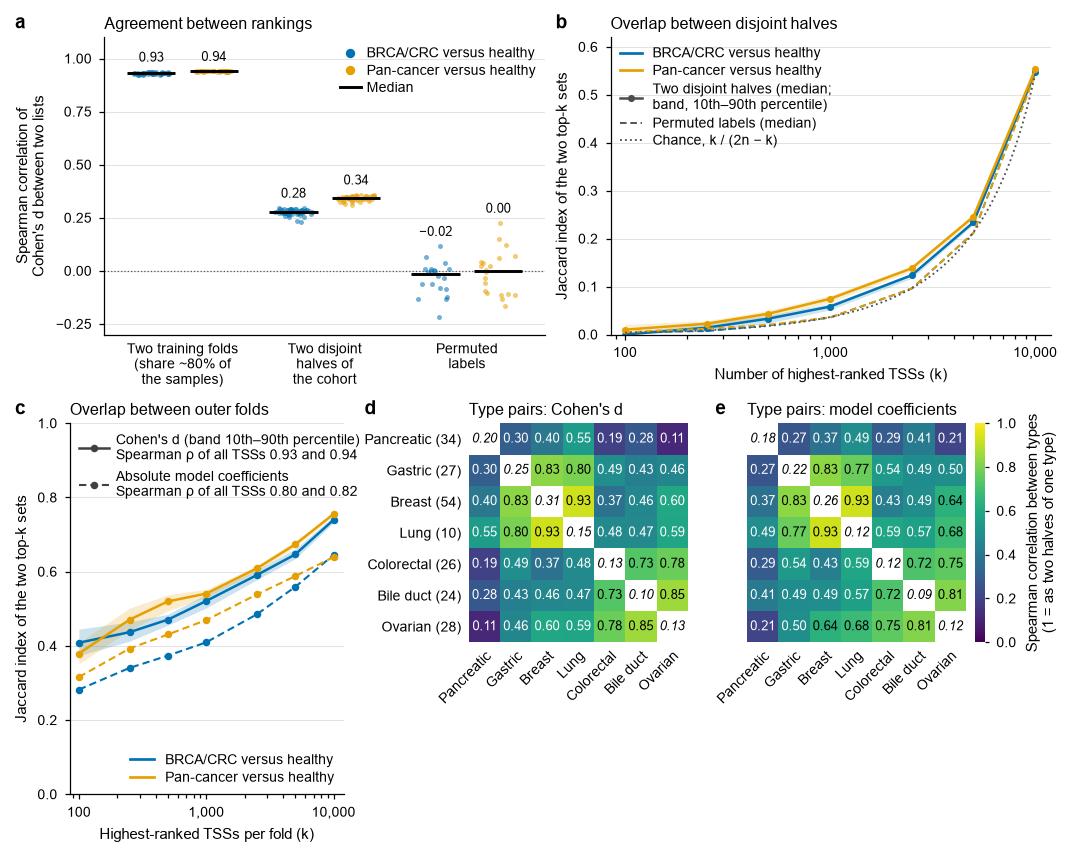

Supplementary figure written to output\no_deep\figS_tss_ranking.png and .pdf (5 panels, 178 x 142 mm)


In [6]:
def task_handles(kind="line", labels=None):
    labels = labels or TASK_LABELS
    if kind == "dot":
        return [Line2D([], [], marker="o", ls="none", color=TASK_COLORS[t], markersize=3.5, label=labels[t]) for t in TASKS]
    if kind == "patch":
        return [mpl.patches.Patch(facecolor=TASK_COLORS[t], alpha=0.55, edgecolor="none", label=labels[t]) for t in TASKS]
    return [Line2D([], [], color=TASK_COLORS[t], lw=1.3, label=labels[t]) for t in TASKS]


LEG = dict(frameon=False, fontsize=FS_SMALL, handlelength=1.8, borderaxespad=0.3, labelspacing=0.3)
def draw_single_tss(ax_dist, ax_q, ax_auroc):
    """The three single-TSS panels (drawn only with SHOW_SINGLE_TSS = True)."""
    # --- distribution of Cohen's d --------------------------------------------------------------
    ax = ax_dist
    bins = np.linspace(-0.70, 0.70, 71)
    peak = 0
    for t in TASKS:
        assert bins[0] < SINGLE[t]["d"].min() and SINGLE[t]["d"].max() < bins[-1]
        n_, _, _ = ax.hist(SINGLE[t]["d"], bins=bins, color=TASK_COLORS[t], alpha=0.55)
        peak = max(peak, n_.max())
    ax.set_xlim(-0.72, 0.72); ax.set_ylim(0, peak * 1.27)
    ax.set_xlabel("Cohen's d (cancer − healthy, dip depth)"); ax.set_ylabel("Number of TSSs")
    ax.legend(handles=task_handles("patch", {t: f"{TASK_LABELS[t]} (median |d| {SINGLE[t]['median_abs_d']:.2f})" for t in TASKS}),
              loc="upper left", **{**LEG, "handlelength": 1.2})
    fs.value_grid(ax)
    ax.set_title(f"Cohen's d of {N_TSS:,} TSSs", loc="left")

    # --- q-value against Cohen's d --------------------------------------------------------------
    ax = ax_q
    for t in TASKS:
        ax.scatter(SINGLE[t]["d"], SINGLE[t]["mlq"], s=1.5, alpha=0.35, color=TASK_COLORS[t], linewidths=0, rasterized=True)
    ax.axhline(-np.log10(0.05), color=fs.CHANCE, ls=":", lw=0.8)
    ax.text(0, -np.log10(0.05) + 0.04, "q = 0.05", ha="center", va="bottom", fontsize=FS_VALUE, color="0.2")
    ax.set_xlim(-0.72, 0.72); ax.set_ylim(0, max(SINGLE[t]["mlq"].max() for t in TASKS) * 1.33)
    ax.set_xlabel("Cohen's d (cancer − healthy)"); ax.set_ylabel("−log$_{10}$ q (Benjamini–Hochberg, Welch t-test)")
    ax.legend(handles=task_handles("dot", {t: f"{TASK_LABELS[t]} ({SINGLE[t]['n_q05']} TSSs at q < 0.05)" for t in TASKS}),
              loc="upper left", handletextpad=0.4, **LEG)
    ax.set_title("q-value of each TSS", loc="left")

    # --- AUROC of each single TSS against its rank by |Cohen's d| ---------------------------------
    ax = ax_auroc
    rk = np.arange(1, N_TSS + 1)
    for t in TASKS:
        ax.scatter(rk, SINGLE[t]["auroc_by_rank"], s=1, alpha=0.12, color=TASK_COLORS[t], linewidths=0, rasterized=True)
    for t in TASKS:
        ax.plot(rk, SINGLE[t]["auroc_running"], color=TASK_COLORS[t], lw=1.3)
    ax.axhline(0.5, color=fs.CHANCE, ls=":", lw=0.8)
    ax.set_xscale("log"); ax.set_xlim(0.8, N_TSS * 1.25); ax.set_ylim(0.49, 0.74)
    ax.set_xticks([1, 10, 100, 1000, 10000]); ax.set_xticklabels(["1", "10", "100", "1,000", "10,000"])
    ax.set_xlabel("Rank by |Cohen's d| (1 = largest)"); ax.set_ylabel("AUROC of a single TSS (either direction)")
    ax.legend(handles=task_handles("line", {t: f"{TASK_LABELS[t]} (best {SINGLE[t]['best_auroc']:.2f})" for t in TASKS})
              + [Line2D([], [], color="0.25", lw=1.3, label=f"running median ({RUN_WINDOW} TSSs)")], loc="upper right", **LEG)
    fs.value_grid(ax)
    ax.set_title("Single-TSS classification", loc="left")


fig = plt.figure(figsize=FIGSIZE, layout="constrained")
fig.get_layout_engine().set(wspace=0.02, hspace=0.04)
ROW = [1.25, 1, 1, 0.045]                   # overlap between folds, the two heat maps, colour bar
# rows: [single TSSs,] agreement between rankings and overlap of two halves, then folds and the heat maps
outer = fig.add_gridspec(3 if SHOW_SINGLE_TSS else 2, 1, height_ratios=([1.15] if SHOW_SINGLE_TSS else []) + [0.85, 1])
if SHOW_SINGLE_TSS:                         # the single-TSS panels in a row on top
    top = outer[0].subgridspec(1, 3, width_ratios=[1, 1, 1])
    ax_single = [fig.add_subplot(top[0, i]) for i in range(3)]
    draw_single_tss(*ax_single)
else:
    ax_single = []
mid = outer[-2].subgridspec(1, 2, width_ratios=[1, 1])
ax_agree, ax_halves = (fig.add_subplot(mid[0, i]) for i in range(2))
row = outer[-1].subgridspec(1, 4, width_ratios=ROW)
ax_folds, ax_types_d, ax_types_w, cax = (fig.add_subplot(row[0, i]) for i in range(4))

# --- agreement: Spearman correlation of Cohen's d between two lists ---------------------------------
ax = ax_agree
rng = np.random.default_rng(1)
fs.value_grid(ax)
for i, (c, lab) in enumerate(A_GROUPS):
    for j, t in enumerate(TASKS):
        v = AGREE[t][c]; x0 = i + (j - 0.5) * 0.44; m = float(np.median(v))
        ax.plot(x0 + (rng.random(len(v)) - 0.5) * 0.26, v, "o", color=TASK_COLORS[t], alpha=0.55, markersize=2.4, markeredgewidth=0, zorder=3)
        ax.plot([x0 - 0.17, x0 + 0.17], [m, m], color="black", lw=1.4, zorder=4, solid_capstyle="butt")
        ax.text(x0, v.max() + 0.035, num(m), ha="center", va="bottom", fontsize=fs.VALUE)
ax.axhline(0, color=fs.CHANCE, lw=0.6, ls=":", zorder=1)
ax.set_xticks(range(len(A_GROUPS)))
ax.set_xticklabels(["Two training folds\n(share ~80% of\nthe samples)", "Two disjoint\nhalves of\nthe cohort", "Permuted\nlabels"])
ax.tick_params(axis="x", length=0)
ax.set_xlim(-0.55, len(A_GROUPS) - 0.45); ax.set_ylim(-0.3, 1.1); ax.set_yticks(np.arange(-0.25, 1.01, 0.25))
ax.set_ylabel("Spearman correlation of\nCohen's d between two lists")
ax.legend(handles=task_handles("dot") + [Line2D([], [], color="black", lw=1.4, label="Median")], loc="upper right", handletextpad=0.4)
fs.panel(ax, LETTER["agree"], "Agreement between rankings")

# --- halves: Jaccard index of the two top-k sets -------------------------------------------------
ax = ax_halves
fs.value_grid(ax)
kk = np.geomspace(TOP_K[0], TOP_K[-1], 200)
ax.plot(kk, chance(kk), ":", color=fs.CHANCE, lw=0.9, zorder=5)
for t in TASKS:
    b = HALF[t]; col = TASK_COLORS[t]
    ax.fill_between(TOP_K, b["half_lo"], b["half_hi"], color=col, alpha=0.18, linewidth=0)
    ax.plot(TOP_K, b["half_med"], "-", marker="o", markersize=2.4, color=col, lw=1.2)
    ax.plot(TOP_K, b["perm_med"], "--", color=col, lw=0.9, dashes=(3.5, 2))
ax.set_xscale("log"); ax.set_xticks([100, 1000, 10000]); ax.set_xticklabels(["100", "1,000", "10,000"])
ax.set_xlim(85, 12000); ax.set_ylim(0, 0.62)
ax.set_xlabel("Number of highest-ranked TSSs (k)"); ax.set_ylabel("Jaccard index of the two top-k sets")
ax.legend(handles=task_handles("line") + [
    Line2D([], [], color=fs.NEUTRAL, lw=1.2, marker="o", markersize=2.4, label="Two disjoint halves (median;\nband, 10th–90th percentile)"),
    Line2D([], [], color=fs.NEUTRAL, lw=0.9, dashes=(3.5, 2), label="Permuted labels (median)"),
    Line2D([], [], color=fs.CHANCE, lw=0.9, ls=":", label="Chance, k / (2n − k)")], loc="upper left")
fs.panel(ax, LETTER["halves"], "Overlap between disjoint halves")


# --- Jaccard index of the top-k sets of two outer folds ---------------------------------------
MS = 2.6                                    # marker size of the line plots
ax = ax_folds
for t in TASKS:
    col = TASK_COLORS[t]; r = FOLD["cohen_d"][t]
    ax.fill_between(TOP_K, r["lo"], r["hi"], color=col, alpha=0.2, linewidth=0)
    ax.plot(TOP_K, r["med"], "-", marker="o", markersize=MS, color=col, lw=1.2)
    ax.plot(TOP_K, FOLD["coef"][t]["med"], "--", marker="o", markersize=MS, color=col, lw=1.0, dashes=(3.5, 2))
ax.set_xscale("log"); ax.set_xticks([100, 1000, 10000]); ax.set_xticklabels(["100", "1,000", "10,000"])
ax.set_xlim(85, 12000); ax.set_ylim(0, 1)
fs.value_grid(ax)
ax.set_xlabel("Highest-ranked TSSs per fold (k)"); ax.set_ylabel("Jaccard index of the two top-k sets")
rho = {s: " and ".join(num(FOLD[s][t]["spearman"]) for t in TASKS) for s in FOLD_SOURCES}
leg_style = ax.legend(handles=[
    Line2D([], [], color="0.25", lw=1.2, marker="o", markersize=MS,
           label=f"Cohen's d (band 10th–90th percentile)\nSpearman ρ of all TSSs {rho['cohen_d']}"),
    Line2D([], [], color="0.25", lw=1.0, marker="o", markersize=MS, dashes=(3.5, 2),
           label=f"Absolute model coefficients\nSpearman ρ of all TSSs {rho['coef']}")],
    loc="upper left", handletextpad=0.5, **{**LEG, "handlelength": 2.2, "labelspacing": 0.45})
ax.add_artist(leg_style)
ax.legend(handles=task_handles("line"), loc="lower right", **LEG)
fs.panel(ax, LETTER["folds"], "Overlap between outer folds")

# --- agreement between pairs of cancer types (two heat maps) ------------------------------------------------
row_lab = [f"{TYPE_LABEL[t]} ({N_TYPE[t]})" for t in TYPE_ORDER]
col_lab = [TYPE_LABEL[t] for t in TYPE_ORDER]
PAIR_TITLES = {"cohen_d": "Type pairs: Cohen's d", "weight": "Type pairs: model coefficients"}
for ax, stat in zip([ax_types_d, ax_types_w], PAIR_STATS):
    A, W = PAIRS[stat]["between"], PAIRS[stat]["within"]
    im = ax.imshow(A, cmap="viridis", vmin=0, vmax=1)
    for i in range(len(TYPE_ORDER)):
        for j in range(len(TYPE_ORDER)):
            if i == j:
                ax.text(j, i, num(W[i]), ha="center", va="center", fontsize=FS_VALUE, style="italic")
            else:
                ax.text(j, i, num(A[i, j]), ha="center", va="center", fontsize=FS_VALUE, color="white" if A[i, j] < 0.6 else "black")
    ax.set_xticks(range(len(col_lab))); ax.set_xticklabels(col_lab, rotation=45, ha="right", rotation_mode="anchor")
    ax.set_yticks(range(len(row_lab)))
    # the rows are the same in both matrices: the type names (with the number of patients) only on the first one
    ax.set_yticklabels(row_lab if stat == "cohen_d" else [])
    ax.tick_params(length=0)
    for s in ax.spines.values():
        s.set_visible(False)
    ax.set_anchor("N")
    fs.panel(ax, LETTER["types_" + stat], PAIR_TITLES[stat])
cb = fig.colorbar(im, cax=cax)
cb.set_label("Spearman correlation between types\n(1 = as two halves of one type)")
cb.outline.set_visible(False)
cb.ax.tick_params(length=2)

# --- freeze the layout, then the colour bar to the height of the (square) matrices; fs.save places the letters --
fig.canvas.draw()
fig.set_layout_engine("none")
pf = ax_types_w.get_position(); pc = cax.get_position()
cax.set_position([pc.x0, pf.y0, pc.width, pf.height])
panel_axes = ax_single + [ax_agree, ax_halves, ax_folds, ax_types_d, ax_types_w]
assert len(panel_axes) == len(PANELS)
for ax, letter in zip(ax_single, LETTER.values()):     # the single-TSS panels (only with SHOW_SINGLE_TSS = True)
    fs.panel(ax, letter, ax.get_title(loc="left"))

fs.save(fig, out_path("figS_tss_ranking"))
plt.show()
print(f"Supplementary figure written to {out_path('figS_tss_ranking.png')} and .pdf "
      f"({len(PANELS)} panels, {FIGSIZE[0] * 25.4:.0f} x {FIGSIZE[1] * 25.4:.0f} mm)")